# Image patching

Load an RGB image and resize it to the experiment's resolution. Change the image path in the next cell to a photo on your machine. The patch extractor only rearranges pixels; normalization happens in the image-loading cell. Choose image dimensions divisible by the patch size.

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch

from utils.patch_embedding import patchify, PatchEmbeddingModel
from utils.visualization import display_patches

torch.manual_seed(0)
np.random.seed(0)

image_size = 224
patch_size = 16
hidden_dim = 192

image = Image.open("data/image_8765cd2c.jpg").convert("RGB").resize((image_size, image_size))

image_tensor = torch.from_numpy(np.array(image)).permute(2, 0, 1).unsqueeze(0).float() / 255.0
results = patchify(image_tensor, patch_size=patch_size)
patches = results["patches"]

print(f"image tensor shape: {image_tensor.shape}")
print(f"patches tensor shape: {patches.shape}")
plt.imshow(image)
plt.axis("off")
plt.show()

# Patch projection, classification token, and learned positions

Create the model once and reuse it. It owns the linear projection, the shared classification token, and one learned position vector per token (including [CLS]). The returned patch embeddings are the raw projection; the complete token sequence also includes [CLS] and positions.

For 224 × 224 RGB images and 16 × 16 patches: [B, 3, 224, 224] → [B, 196, 768] → [B, 196, 192] → [B, 197, 192].

In [ ]:
patch_embedder = PatchEmbeddingModel(
    embedding_dim=results["embedding_dim"],
    hidden_dim=hidden_dim,
    num_patches=patches.size(1),
)
embedded_patches = patch_embedder(patches)

print(f"projected patches: {embedded_patches['embedded_patches'].shape}")
print(f"encoder input ([CLS] + patches + positions): {embedded_patches['patches_with_cls_token'].shape}")
print(f"shared classification parameter: {embedded_patches['cls_token'].shape}")
print(f"learned positions: {embedded_patches['positional_encoding'].shape}")

# Transformer encoder

Build one encoder block with token width 192, three attention heads, and an MLP width of 768 (four times the token width). Each head has width 64. This is a shallow ViT for learning, not one of the original paper's depth configurations.

The ViT block normalizes before each sublayer: input → LayerNorm → attention → residual addition → LayerNorm → MLP → residual addition. The residual paths bypass normalization. Apply a final LayerNorm after the encoder; if we later add more blocks, it still belongs after the whole stack.

In [ ]:
from utils.transformer_encoder import TransformerEncoderLayer

transformer_encoder = TransformerEncoderLayer(hidden_dim=hidden_dim, num_heads=3, feedforward_dim=hidden_dim * 4, dropout=0.1)
encoder_norm = torch.nn.LayerNorm(hidden_dim)

# The classification MLP head

Select the final normalized [CLS] representation and map it to ten class logits: [B, 192] → [B, 768] → [B, 10]. The hidden width is an experiment choice. We keep the GELU activation you implemented; the original ViT implementation used tanh in its optional hidden classification layer.

The head returns raw logits. Cross-entropy handles their conversion to log probabilities internally. Use softmax separately to display probabilities; do not feed those probabilities into cross-entropy.

References: [original ViT, §3.1 and Eq. 4](https://arxiv.org/html/2010.11929v2#S3.SS1), [official classification head](https://github.com/google-research/vision_transformer/blob/main/vit_jax/models_vit.py), [PyTorch cross-entropy](https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html).

In [ ]:
from utils.mlp_head import MLPHead

mlp_head = MLPHead(input_dim=hidden_dim, hidden_dim=hidden_dim * 4, output_dim=10)

# Gradient flow through the classification model

This runs the complete path: patch projection → [CLS] and positions → encoder → final LayerNorm → [CLS] selection → classification head → cross-entropy. The target below is an arbitrary demonstration label, not a label inferred from the photo. Backpropagation shows connectivity; no optimizer step or training occurs here.

We report each parameter's L2 gradient norm and RMS (norm divided by the square root of its element count). Each component's combined norm, and the full-model norm, are the square root of the sum of the corresponding squared parameter norms. RMS helps account for tensor size; these values still do not rank component importance.

Key-bias gradients can be zero because their common offset cancels in attention softmax. Gradient magnitudes depend on the image, target, initialization, dropout, and loss; there is no universal good value.

In [ ]:
model_components = (
    ("patch_embedder", patch_embedder),
    ("transformer_encoder", transformer_encoder),
    ("encoder_norm", encoder_norm),
    ("mlp_head", mlp_head),
)
for _, component in model_components:
    component.train()
    component.zero_grad()

embedding_outputs = patch_embedder(patches)
encoder_inputs = embedding_outputs["patches_with_cls_token"]
encoded_tokens = transformer_encoder(encoder_inputs)
normalized_tokens = encoder_norm(encoded_tokens)
cls_representation = normalized_tokens[:, 0, :]
classification_logits = mlp_head(cls_representation)
classification_probabilities = classification_logits.detach().softmax(dim=-1)

print(f"encoder input: {encoder_inputs.shape}")
print(f"encoder output: {encoded_tokens.shape}")
print(f"normalized classification-token representation: {cls_representation.shape}")
print(f"classification logits: {classification_logits.shape}")
print(f"display probabilities sum: {classification_probabilities.sum(dim=-1)}")

# Placeholder class 0: this only demonstrates the classification gradient path.
# Replace it with real labels for a training experiment.
demo_targets = torch.zeros(patches.size(0), dtype=torch.long, device=patches.device)
loss = torch.nn.functional.cross_entropy(classification_logits, demo_targets)
loss.backward()
print(f"demonstration cross-entropy loss: {loss.item():.6f}")

component_norms = []
for component_name, component in model_components:
    parameter_norms = []
    for name, parameter in component.named_parameters():
        gradient_norm = parameter.grad.norm()
        gradient_rms = gradient_norm / (parameter.numel() ** 0.5)
        parameter_norms.append(gradient_norm)
        print(f"{component_name}.{name}: shape={tuple(parameter.shape)}, "
              f"gradient norm={gradient_norm.item():.6f}, RMS={gradient_rms.item():.6f}")
    component_norm = torch.stack(parameter_norms).norm()
    component_norms.append(component_norm)
    print(f"{component_name} combined gradient norm: {component_norm.item():.6f}")

full_gradient_norm = torch.stack(component_norms).norm()
print(f"full model gradient norm: {full_gradient_norm.item():.6f}")

# Experiments for Part 1

The earlier plan was: visualize patches; measure how attention cost changes with patch size; and compare a small ViT with a CNN trained from scratch. Comparing pretrained features was optional. We also planned to overfit a tiny batch before attempting the dataset comparison. A later learned-versus-sinusoidal-position comparison is still available; the active model continues to use learned positions.

The checks below collect the first results. They use fresh model instances so the earlier gradient demonstration is not trained accidentally. The CNN comparison still needs a dataset, training/validation/test split, model sizes, and training budget; no real-image accuracy results are claimed here.

# Experiment 1: visualize patch size

Keep the image fixed and change only the patch size. Each row below shows five sampled patches. Smaller patches produce more tokens and cover less of the image individually. The projected token width remains a separate model choice.

In [ ]:
for visual_patch_size in (8, 16, 32):
    visual_patches = patchify(image_tensor, visual_patch_size)["patches"]
    print(f"{visual_patch_size} × {visual_patch_size} patches: "
          f"{visual_patches.size(1)} image tokens, "
          f"{visual_patches.size(-1)} pixel values per patch")
    display_patches(visual_patches, patch_size=visual_patch_size)

# Sanity check: memorize a tiny labeled batch

Create ten fixed 32 × 32 RGB patterns, one per class. Each has an 8 × 8 colored square at a class-dependent position plus small fixed noise. Use 8 × 8 patches (17 tokens including [CLS]), width 192, three heads, one encoder block, and the same classification-head design.

Train on these same ten images for 300 updates with AdamW, learning rate 0.0005, weight decay zero, dropout 0.1, and seed 17. Evaluate this training batch with dropout disabled at the recorded steps. A previous short trial at learning rate 0.002 was unstable (70% at step 60); the lower rate below is a debugging choice, not a benchmark tuning result.

Reaching 100% here demonstrates memorization and basic optimization. It does not establish generalization, compare CNNs, or reproduce the original ViT paper. The resolution and token count differ from the 224 × 224 demonstration.

step   0: training loss=2.320141, training accuracy=10%
step   1: training loss=2.289770, training accuracy=10%
step  20: training loss=1.205595, training accuracy=60%
step  50: training loss=0.250458, training accuracy=100%
step 100: training loss=0.000917, training accuracy=100%
step 200: training loss=0.000361, training accuracy=100%
step 300: training loss=0.000215, training accuracy=100%


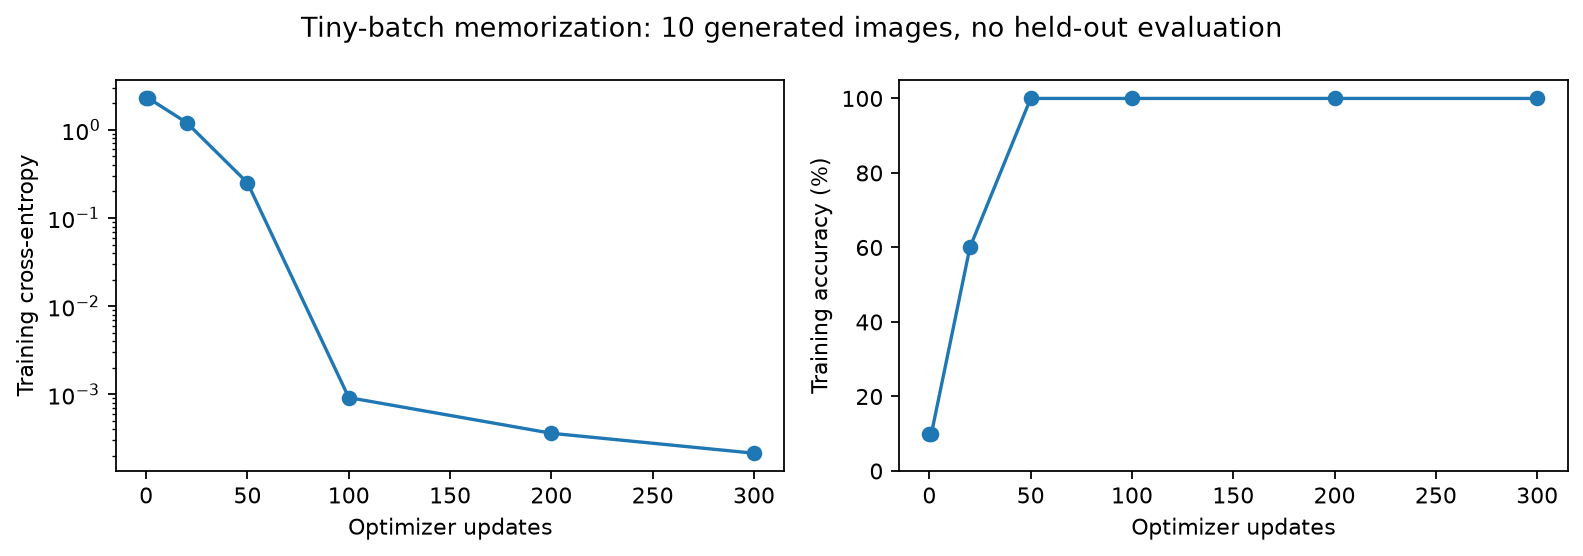

In [7]:
torch.manual_seed(17)
sanity_images = torch.full((10, 3, 32, 32), 0.05)
sanity_targets = torch.arange(10)
for label in range(10):
    row, col = divmod(label, 4)
    sanity_images[label, label % 3, row * 8:(row + 1) * 8, col * 8:(col + 1) * 8] = 0.95
    sanity_images[label] += 0.01 * torch.randn_like(sanity_images[label])
sanity_images.clamp_(0, 1)
sanity_patches = patchify(sanity_images, patch_size=8)["patches"]

sanity_model = torch.nn.ModuleDict({
    "patch_embedder": PatchEmbeddingModel(3 * 8 ** 2, hidden_dim=192, num_patches=16),
    "encoder": TransformerEncoderLayer(192, 3, 768, dropout=0.1),
    "final_norm": torch.nn.LayerNorm(192),
    "head": MLPHead(192, 768, 10),
})

def sanity_logits():
    tokens = sanity_model["patch_embedder"](sanity_patches)["patches_with_cls_token"]
    tokens = sanity_model["encoder"](tokens)
    cls = sanity_model["final_norm"](tokens)[:, 0, :]
    return sanity_model["head"](cls)

optimizer = torch.optim.AdamW(sanity_model.parameters(), lr=0.0005, weight_decay=0.0)
sanity_history = []
for step in range(301):
    if step > 0:
        sanity_model.train()
        optimizer.zero_grad()
        sanity_loss = torch.nn.functional.cross_entropy(sanity_logits(), sanity_targets)
        sanity_loss.backward()
        optimizer.step()
    if step in (0, 1, 20, 50, 100, 200, 300):
        sanity_model.eval()
        with torch.no_grad():
            logits = sanity_logits()
            loss_value = torch.nn.functional.cross_entropy(logits, sanity_targets).item()
            accuracy = (logits.argmax(dim=-1) == sanity_targets).float().mean().item()
        sanity_history.append({"step": step, "loss": loss_value, "training_accuracy": accuracy})
        print(f"step {step:3d}: training loss={loss_value:.6f}, training accuracy={accuracy:.0%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot([r["step"] for r in sanity_history], [r["loss"] for r in sanity_history], marker="o")
axes[0].set(xlabel="Optimizer updates", ylabel="Training cross-entropy", yscale="log")
axes[1].plot([r["step"] for r in sanity_history], [100 * r["training_accuracy"] for r in sanity_history], marker="o")
axes[1].set(xlabel="Optimizer updates", ylabel="Training accuracy (%)", ylim=(0, 105))
fig.suptitle("Tiny-batch memorization: 10 generated images, no held-out evaluation")
fig.tight_layout()
plt.show()

# Experiment 2: patch size and attention scaling

For a 224 × 224 image and patch width P, the token count including [CLS] is N = (224/P)² + 1. A head has an N × N score matrix, so the total logical score count across h heads is hN². The quadratic dependence is on token count; at fixed image size, the leading dependence on patch width is approximately P⁻⁴.

Time the existing multi-head attention module, including its Q/K/V and output projections, at batch size one, width 192, and three heads. Use CPU float32, two threads, inference mode, three warmups, and seven timed repeats; report the median. This benchmark excludes patch extraction, embedding, the encoder MLP, backward, and data loading. The full module also has linear-in-N work, so measured latency need not follow N² exactly.

The reported FP32 MiB is the sum of three logical score-matrix sizes. It is not measured peak memory; sequential heads and softmax intermediates have different live allocations. Timings describe this machine and this implementation.

PyTorch 2.15.0; arm64; CPU float32; batch 1; 2 threads
patch | tokens | score entries (3 heads) | logical FP32 MiB | median forward ms
   32 |     50 |                   7,500 |            0.029 |             0.102
   16 |    197 |                 116,427 |            0.444 |             0.283
    8 |    785 |               1,848,675 |            7.052 |             1.673
    4 |   3137 |              29,522,307 |          112.619 |            22.159


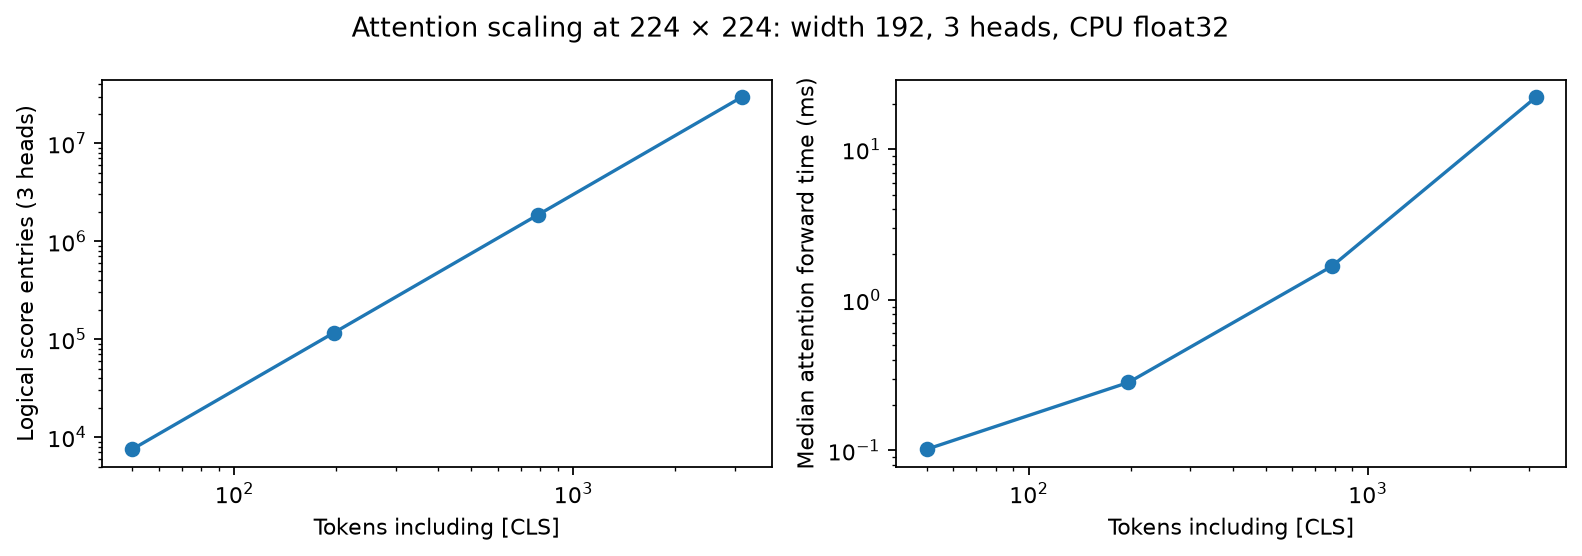

In [8]:
import platform
from statistics import median
from time import perf_counter_ns
from utils.transformer_encoder import MultiHeadSelfAttention

previous_threads = torch.get_num_threads()
torch.set_num_threads(2)
torch.manual_seed(0)
scaling_attention = MultiHeadSelfAttention(hidden_dim=192, num_heads=3).eval()
scaling_results = []
with torch.inference_mode():
    for scaling_patch_size in (32, 16, 8, 4):
        token_count = (224 // scaling_patch_size) ** 2 + 1
        scaling_input = torch.randn(1, token_count, 192)
        for _ in range(3):
            scaling_attention(scaling_input)
        elapsed_ms = []
        for _ in range(7):
            start_ns = perf_counter_ns()
            scaling_attention(scaling_input)
            elapsed_ms.append((perf_counter_ns() - start_ns) / 1_000_000)
        score_entries = 3 * token_count ** 2
        scaling_results.append({
            "patch_size": scaling_patch_size,
            "tokens": token_count,
            "score_entries": score_entries,
            "score_capacity_mib": score_entries * 4 / 2 ** 20,
            "median_forward_ms": median(elapsed_ms),
            "samples_ms": elapsed_ms,
        })
torch.set_num_threads(previous_threads)

print(f"PyTorch {torch.__version__}; {platform.machine()}; CPU float32; batch 1; 2 threads")
print("patch | tokens | score entries (3 heads) | logical FP32 MiB | median forward ms")
for row in scaling_results:
    print(f"{row['patch_size']:5d} | {row['tokens']:6d} | {row['score_entries']:23,d} | "
          f"{row['score_capacity_mib']:16.3f} | {row['median_forward_ms']:17.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot([r["tokens"] for r in scaling_results], [r["score_entries"] for r in scaling_results], marker="o")
axes[0].set(xlabel="Tokens including [CLS]", ylabel="Logical score entries (3 heads)", xscale="log", yscale="log")
axes[1].plot([r["tokens"] for r in scaling_results], [r["median_forward_ms"] for r in scaling_results], marker="o")
axes[1].set(xlabel="Tokens including [CLS]", ylabel="Median attention forward time (ms)", xscale="log", yscale="log")
fig.suptitle("Attention scaling at 224 × 224: width 192, 3 heads, CPU float32")
fig.tight_layout()
plt.show()